# CodeGuard AI · Experiment 05b: Python model version 2

Experiment 05 (model v1) showed three problems in the data:
1. Many methods exist only *after* the fix — mostly **new tests** — and are labelled "fixed". The model learned "looks like a test → safe".
2. Test methods edited by a fix are labelled "vulnerable", although they are not unsafe code.
3. Some "pairs" did not change at all in the fix.

And one problem in how the model is used: the F1-optimal threshold flagged **83%** of safe methods.

**Version 2 changes (decided from v1's analysis, before looking at any v2 result):**
- Keep only **true pairs**: the same method (commit + file + name) with exactly one version before and one after the fix.
- Drop pairs whose code did not change (ignoring whitespace).
- Drop **test code** (test files, `tests/` folders, `test*` methods, `setUp`/`tearDown`).
- Choose the scanner threshold on training data with a **false-positive cap of 10%**.
- Add a **pairwise** score: within each pair, does the vulnerable version score higher than its fix?

> **Honesty note:** the v1 test set has been seen. v2 uses the same seed and the same repository-grouped method, so many test repositories overlap with v1. Treat v2's test result as a *second look* at held-out repositories, reported separately from v1 — not as an untouched final exam.

In [1]:
import json
import re
import shutil
import time
import warnings
from datetime import date
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, roc_curve)
from sklearn.calibration import CalibrationDisplay

warnings.filterwarnings("ignore")
SEED = 42
ART = Path("../artifacts")
MAX_FPR = 0.10

## Step 1: Build the paired, test-free dataset

In [2]:
raw = pd.read_csv("../datasets/processed/python_functions.csv")
KEY = ["commit_hash", "file_path", "method_name"]
print("Extracted methods:", len(raw))

# 1. True pairs: exactly one version before and one after the fix
sizes = raw.groupby(KEY)["target"].agg(n="size", vulnerable="sum")
pair_keys = sizes[(sizes["n"] == 2) & (sizes["vulnerable"] == 1)].index
pairs = raw.set_index(KEY).loc[pair_keys].reset_index()
print("Methods in true pairs:", len(pairs), f"({len(pair_keys)} pairs)")

# 2. Drop pairs whose code did not change
pairs["code_key"] = pairs["func"].str.replace(r"\s+", "", regex=True)
changed = pairs.groupby(KEY)["code_key"].nunique() == 2
pairs = pairs.set_index(KEY).loc[changed[changed].index].reset_index()
print("After dropping unchanged pairs:", len(pairs))

# 3. Drop test code
TEST_PATH = re.compile(r"(^|/)(tests?|testing|unit_tests)/|(^|/)test_[^/]*\.py$|_tests?\.py$|(^|/)conftest\.py$")
TEST_NAME = re.compile(r"^(test|_test|setUp|tearDown|setUpClass|tearDownClass)")
is_test = pairs["file_path"].str.contains(TEST_PATH) | pairs["method_name"].str.contains(TEST_NAME)
pairs = pairs[~pairs.groupby(KEY)["file_path"].transform(lambda s: is_test.loc[s.index].any())]
print("After dropping test code:", len(pairs))

# 4. Code that appears with both labels anywhere (copied between pairs) is unusable
conflict = pairs.groupby("code_key")["target"].nunique()
pairs = pairs[~pairs["code_key"].isin(conflict[conflict > 1].index)]
complete = pairs.groupby(KEY)["target"].transform("size") == 2
pairs = pairs[complete].copy()
pairs["pair_id"] = pairs.groupby(KEY).ngroup()

df = pairs.reset_index(drop=True)
print()
print("v2 dataset:", len(df), "methods =", df["pair_id"].nunique(), "pairs |",
      df["repo_url"].nunique(), "repositories |", df["cve_id"].nunique(), "CVEs")
print(df["target"].value_counts().rename({0: "fixed", 1: "vulnerable"}))

Extracted methods: 7568
Methods in true pairs: 4724 (2362 pairs)
After dropping unchanged pairs: 4470


After dropping test code: 3080

v2 dataset: 2920 methods = 1460 pairs | 341 repositories | 535 CVEs
target
fixed         1460
vulnerable    1460
Name: count, dtype: int64


**Balanced by construction:** every vulnerable method has exactly one fixed partner, so a model that always guesses one class gets 50% accuracy and PR-AUC ≈ 0.5.

In [3]:
diff_lines = df.groupby("pair_id").apply(
    lambda g: len(set(g.loc[g.target == 1, "func"].iloc[0].splitlines()) ^ set(g.loc[g.target == 0, "func"].iloc[0].splitlines())))
print("Lines that differ between the two versions of a pair (median):", int(diff_lines.median()))
print("Pairs differing in at most 2 lines:", f"{(diff_lines <= 2).mean():.0%}")

Lines that differ between the two versions of a pair (median): 5
Pairs differing in at most 2 lines: 31%


This number explains how hard the task is: the vulnerable and fixed versions share almost all of their words.

## Step 2: Split by repository (same method and seed as v1)

In [4]:
X, y, groups = df["func"], df["target"], df["repo_url"]
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]
print(f"Training: {len(X_train)} methods | Test: {len(X_test)} methods")
print("Repositories in both:", len(set(groups_train) & set(groups.iloc[test_idx])))
print("Pairs split across sides:", len(set(df.iloc[train_idx]["pair_id"]) & set(df.iloc[test_idx]["pair_id"])))

Training: 2194 methods | Test: 726 methods
Repositories in both: 0
Pairs split across sides: 0


## Step 3: Compare models with grouped cross-validation (training data only)

In [5]:
TOKEN_PATTERN = r"[A-Za-z_]\w*|\d+|==|!=|<=|>=|\*\*|[%+\-*/=<>()\[\]{}.,:'\"]"

def make_tfidf():
    return TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=False, ngram_range=(1, 2),
                           max_features=20000, min_df=2, sublinear_tf=True)

models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000, C=1.0),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method="hist",
                             eval_metric="logloss", random_state=SEED, n_jobs=-1),
}
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv = GroupKFold(n_splits=5)
rows = []
for name, model in models.items():
    start = time.time()
    s = cross_validate(make_pipeline(make_tfidf(), model), X_train, y_train, groups=groups_train, cv=cv, scoring=scoring)
    rows.append({"Model": name, **{m: s[f"test_{m}"].mean() for m in scoring}, "Seconds": time.time() - start})
comparison = pd.DataFrame(rows).set_index("Model").round(3)
best_name = comparison.drop(index="Baseline (majority)")["roc_auc"].idxmax()
print("Chosen by cross-validated ROC-AUC:", best_name)
comparison

Chosen by cross-validated ROC-AUC: Logistic Regression


,accuracy,precision,recall,f1,roc_auc,pr_auc,Seconds
Model,,,,,,,
Baseline (majority),0.500,0.000,0.000,0.000,0.500,0.500,3.940
Logistic Regression,0.543,0.547,0.533,0.538,0.553,0.552,3.995
Random Forest,0.521,0.520,0.575,0.545,0.536,0.539,7.813
XGBoost,0.536,0.537,0.548,0.540,0.548,0.549,46.480


With balanced classes, ROC-AUC and PR-AUC tell the same story; we choose by ROC-AUC.

## Step 4: Threshold with a false-positive cap (training data only)

The scanner should not bury users in false alarms. On out-of-fold training predictions we take the **lowest threshold whose false-positive rate is at most 10%**, which gives the highest recall allowed under that cap.

In [6]:
oof = cross_val_predict(make_pipeline(make_tfidf(), models[best_name]), X_train, y_train,
                        groups=groups_train, cv=cv, method="predict_proba")[:, 1]
fpr, tpr, thr = roc_curve(y_train, oof)
ok = np.where(fpr <= MAX_FPR)[0]
best = ok[np.argmax(tpr[ok])]
threshold = float(min(round(thr[best], 4), 1.0))
print(f"Threshold {threshold}: out-of-fold FPR {fpr[best]:.3f}, recall {tpr[best]:.3f}")

Threshold 0.5456: out-of-fold FPR 0.098, recall 0.126


## Step 5: Test on held-out repositories

In [7]:
final_model = make_pipeline(make_tfidf(), models[best_name]).fit(X_train, y_train)
score = final_model.predict_proba(X_test)[:, 1]
pred = (score >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

test_df = df.iloc[test_idx].assign(score=score, pred=pred)
paired = test_df.pivot_table(index="pair_id", columns="target", values="score")
pairwise = float((paired[1] > paired[0]).mean())

test_metrics = {
    "test_size": int(len(y_test)), "test_pairs": int(len(paired)),
    "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0),
    "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
    "roc_auc": roc_auc_score(y_test, score), "pr_auc": average_precision_score(y_test, score),
    "false_positive_rate": fp / (fp + tn), "pairwise_accuracy": pairwise,
    "baseline_accuracy": 0.5, "baseline_pr_auc": float(y_test.mean()), "baseline_pairwise": 0.5,
}
test_metrics = {k: (round(v, 3) if isinstance(v, float) else v) for k, v in test_metrics.items()}
pd.Series(test_metrics)

test_size              726.000
test_pairs             363.000
accuracy                 0.511
precision                0.561
recall                   0.102
f1                       0.172
roc_auc                  0.544
pr_auc                   0.537
false_positive_rate      0.080
pairwise_accuracy        0.587
baseline_accuracy        0.500
baseline_pr_auc          0.500
baseline_pairwise        0.500
dtype: float64

**Pairwise accuracy** asks the most direct question: shown a vulnerable method and its fix, does the model give the vulnerable one the higher score? A coin flip gets 0.5.

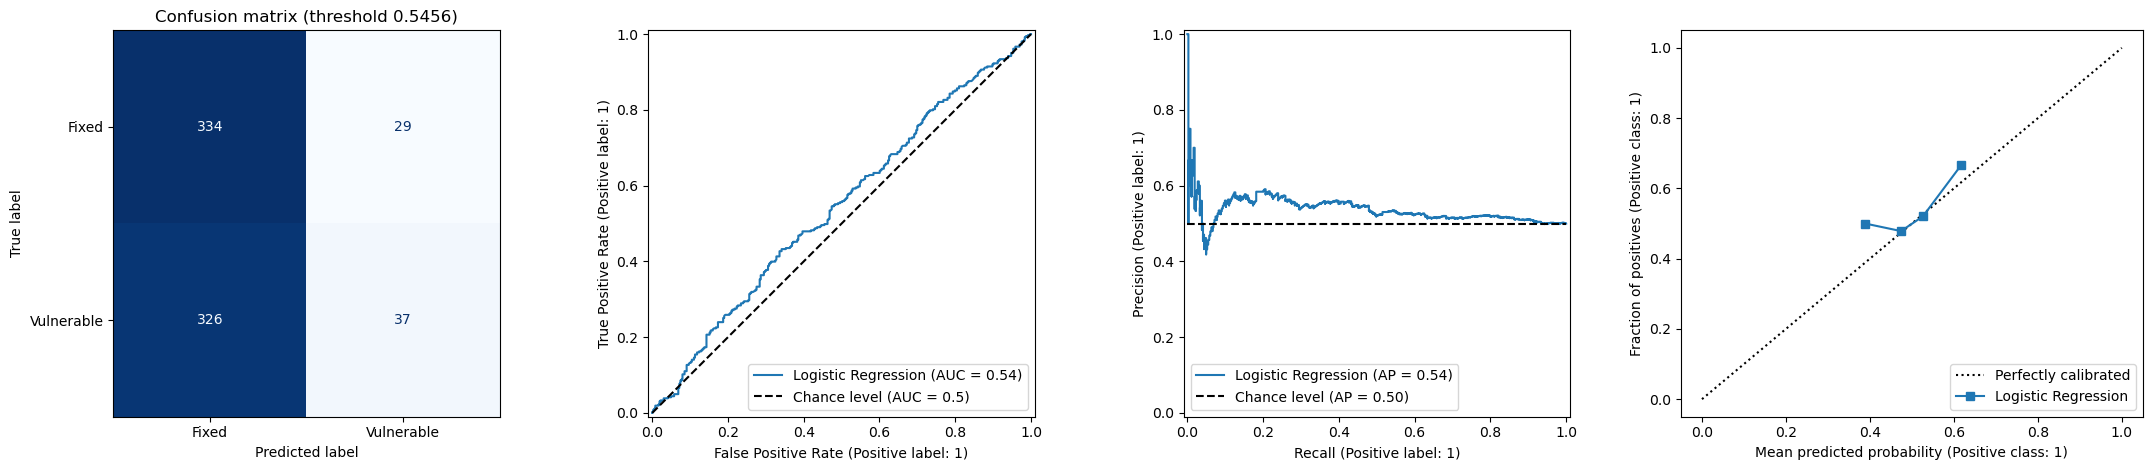

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Fixed", "Vulnerable"], cmap="Blues",
                                        ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix (threshold {threshold})")
RocCurveDisplay.from_predictions(y_test, score, ax=axes[1], name=best_name, plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_test, score, ax=axes[2], name=best_name, plot_chance_level=True)
CalibrationDisplay.from_predictions(y_test, score, n_bins=10, ax=axes[3], name=best_name)
plt.tight_layout()
plt.savefig(ART / "figures" / "python_v2_test_curves.png", dpi=120)
plt.show()

## Step 6: v1 and v2 side by side

In [9]:
v1 = json.loads((ART / "metrics" / "python_results.json").read_text())["test_metrics"]
side = pd.DataFrame({"v1 (all methods, F1 threshold)": v1, "v2 (pairs, no tests, FPR cap)": test_metrics}).loc[
    ["test_size", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "false_positive_rate",
     "baseline_accuracy", "baseline_pr_auc"]]
side

,"v1 (all methods, F1 threshold)","v2 (pairs, no tests, FPR cap)"
test_size,1458.000,726.000
accuracy,0.441,0.511
precision,0.392,0.561
recall,0.899,0.102
f1,0.546,0.172
roc_auc,0.553,0.544
pr_auc,0.417,0.537
false_positive_rate,0.833,0.080
baseline_accuracy,0.626,0.500
baseline_pr_auc,0.374,0.500


Note the baselines differ (v1 is 37% vulnerable, v2 is 50%), so compare each model against its own baseline — especially ROC-AUC, which does not depend on class balance.

## Step 7: Which tokens does v2 rely on?

In [10]:
est = final_model[-1]
names = final_model[0].get_feature_names_out()
weights = pd.Series(np.ravel(est.coef_), index=names) if hasattr(est, "coef_") else pd.Series(est.feature_importances_, index=names)
print("Top tokens pointing to VULNERABLE:")
print(weights.nlargest(15).round(3).to_string())
print()
print("Top tokens pointing to FIXED:" if hasattr(est, "coef_") else "")
if hasattr(est, "coef_"):
    print(weights.nsmallest(15).round(3).to_string())

Top tokens pointing to VULNERABLE:
fileio .            0.958
fileio              0.952
. _path             0.901
_path               0.901
return redirect     0.836
value }             0.809
{ value             0.797
. Custom_Columns    0.774
Custom_Columns      0.774
redirect (          0.748
with fileio         0.737
. like              0.698
redirect            0.688
like (              0.684
return os           0.674

Top tokens pointing to FIXED:
artifact_store         -1.307
return safe_redirect   -1.133
safe_redirect          -1.133
safe_redirect (        -1.133
. _filesystem_path     -1.037
_filesystem_path       -1.037
safe_join              -1.015
safe_join (            -1.015
filesystem_path        -0.914
ignore_prefix          -0.842
, '                    -0.796
escape                 -0.775
artifact_store .       -0.770
. CustomColumns        -0.731
CustomColumns          -0.731


## Step 8: Save v2 as the scanner model (v1 is archived)

In [11]:
model_dir = ART / "model"
(model_dir / "v1").mkdir(exist_ok=True)
for name in ("python_vuln_model.joblib", "model_card.json"):
    if (model_dir / name).exists() and not (model_dir / "v1" / name).exists():
        shutil.copy2(model_dir / name, model_dir / "v1" / name)

joblib.dump(final_model, model_dir / "python_vuln_model.joblib")
card = {
    "model_version": f"py-tfidf-{best_name.split()[0].lower()}-v2-{date.today():%Y%m%d}",
    "language": "python",
    "algorithm": best_name,
    "features": "TF-IDF on Python identifier and symbol tokens, 1-2 grams, 20k max features",
    "training_data": "CVEfixes v1.0.8 Python methods: true before/after pairs only, changed code only, test code removed",
    "split": "GroupShuffleSplit by repository 80/20 (seed 42); model chosen by 5-fold GroupKFold ROC-AUC",
    "train_size": int(len(X_train)), "test_size": int(len(X_test)),
    "threshold": threshold, "threshold_method": f"highest recall with out-of-fold training FPR <= {MAX_FPR}",
    "cross_validation": comparison.reset_index().to_dict(orient="records"),
    "test_metrics": test_metrics,
    "test_set_note": "Second look at repository-held-out data after v1; report separately from v1.",
    "previous_version": json.loads((model_dir / "v1" / "model_card.json").read_text()).get("model_version"),
    "sklearn_version": sklearn.__version__,
    "created": date.today().isoformat(),
    "limitations": [
        "Scores whole methods; cannot point to the exact unsafe line.",
        "Score is a resemblance to vulnerable training examples, not a probability of exploitability.",
        "Trained on CVE-fix commits; labels contain noise.",
        "Python only; not trained on test code.",
    ],
}
(model_dir / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
(ART / "metrics" / "python_results_v2.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
print("Saved v2 model and card; v1 archived in artifacts/model/v1/")

Saved v2 model and card; v1 archived in artifacts/model/v1/


## Conclusion

| Test, repository-held-out | Methods | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC | FPR | Pairwise |
|---|---|---|---|---|---|---|---|---|---|
| v1 baseline (always "fixed") | 1,458 | 0.626 | — | 0 | 0 | 0.5 | 0.374 | 0 | — |
| v1: all methods, F1 threshold 0.311 | 1,458 | 0.441 | 0.392 | 0.899 | 0.546 | 0.553 | 0.417 | 0.833 | — |
| v2 baseline (always one class) | 726 | 0.500 | — | — | — | 0.5 | 0.500 | — | 0.500 |
| **v2: true pairs, no tests, FPR-capped threshold 0.546** | 726 | 0.511 | 0.561 | 0.102 | 0.172 | 0.544 | 0.537 | **0.080** | **0.587** |

1. **Data:** 1,460 true vulnerable/fixed pairs (2,920 methods, 341 repositories, 535 CVEs) after removing unpaired methods, unchanged pairs and test code. The median pair differs in only 5 lines; 31% differ in 2 lines or fewer.
2. **Ranking quality did not improve:** ROC-AUC 0.544 vs 0.553 in v1 — still only slightly better than chance. Cleaning removed the test-code shortcut, so this is a more honest measure of what TF-IDF can do.
3. **Usability improved a lot:** with the 10% false-positive cap chosen on training data, the test false-positive rate is 8% (v1: 83%). The price is low recall (10%): the model flags few methods, but when it does, 56% are truly the vulnerable version.
4. **Pairwise accuracy 0.587:** given a vulnerable method and its fix, the model ranks the vulnerable one higher 59% of the time (chance 50%).
5. **The model now learns real security vocabulary:** `safe_redirect`, `safe_join`, `escape` point to *fixed*; `redirect(`, raw `_path` / `fileio` access point to *vulnerable*. Some project names remain (`artifact_store`, `CustomColumns`).
6. **Decision:** v2 replaces v1 in the scanner because it produces far fewer false alarms. ML findings stay Informational and unconfirmed. v1 is archived in `artifacts/model/v1/`.

**Caveat:** this is the second evaluation on repository-held-out data with the same seed, after v1 was seen; it is reported separately and is not an untouched final test. A truly fresh check will come from the hand-labelled fixtures and the final system evaluation (Experiment 08).